# $S_{\mathrm{quantum}}$ workflow for 3 experiments

This notebook shows only data flow and calls to shared functions. Metric formulas, terminal-measurement stripping, common-basis transpilation, functional routing, and generation aggregation are maintained in `s_quantum_utils.py`.

The reported object is the three-axis vector

$$
S_{\mathrm{quantum}}=(s_{\mathrm{gate}},s_{\mathrm{struct}},f),
$$

not a scalar maximum.

## Overall Metric contract

| Metric | Measurement handling | Representation / method |
|---|---|---|
| $s_{\mathrm{gate}}$ | Strip terminal measurements only; retain mid-circuit measurements and other operations | Operation-count cosine; transpiled result is primary, raw result is sensitivity |
| $s_{\mathrm{struct}}$ | Same structural view as $s_{\mathrm{gate}}$ | Canonical-anchored per-wire k-gram/LCS coverage |
| $f$, no measurement | No | Process fidelity |
| $f$, terminal measurement | Strip terminal measurements inside the evaluator | Exact measured-output probability similarity from Statevector; no shots |
| $f$, mid-circuit measurement | No | Return `None`/`NaN` with an explicit unsupported status until the simulation policy is confirmed |

Common basis: `{rz, sx, x, cx}`; `optimization_level=0`; `seed_transpiler=42`.

 Return `None`/`NaN` with an explicit unsupported status？？？

In [38]:
import importlib, s_quantum_utils
importlib.reload(s_quantum_utils)

from s_quantum_utils import (
    COMMON_BASIS,
    COMMON_OPTIMIZATION_LEVEL,
    COMMON_TRANSPILE_SEED,
    TASK_EXTRA_ARGS,
    aggregate_valid_generations,
    build_exc_record,
    compute_pair_metrics,
    exec_code,
    extract_args_recorder,
    make_failed_pair_metrics,
    reconstruct_full_code,
    s_quantum_axes,
)

## Overall Mearsure Function contract

Every experiment first produces one `reference_qc` and one `candidate_qc`. The same utility call then computes raw/transpiled $s_{\mathrm{gate}}$, raw/transpiled $s_{\mathrm{struct}}$, and $f$. `reference_qc` is always the canonical anchor.




In [17]:
"""
pair_metrics = compute_pair_metrics(
    reference_qc=reference_qc,
    candidate_qc=candidate_qc,
    basis_gates=COMMON_BASIS,
    optimization_level=COMMON_OPTIMIZATION_LEVEL,
    seed_transpiler=COMMON_TRANSPILE_SEED,
    n_parameter_samples=50,
    parameter_seed=42,
)
quantum_axes = s_quantum_axes(pair_metrics, representation="transpiled")
"""

'\npair_metrics = compute_pair_metrics(\n    reference_qc=reference_qc,\n    candidate_qc=candidate_qc,\n    basis_gates=COMMON_BASIS,\n    optimization_level=COMMON_OPTIMIZATION_LEVEL,\n    seed_transpiler=COMMON_TRANSPILE_SEED,\n    n_parameter_samples=50,\n    parameter_seed=42,\n)\nquantum_axes = s_quantum_axes(pair_metrics, representation="transpiled")\n'

## Experiment 1: Corpus Detection

Each corpus snippet is loaded from the pre-processed JSON files (`qhe_corpus_snippets.json`, `qb_corpus_snippets.json`).  `corpus_snippet_realigned` is used when available (syntax fixed by indent realignment); otherwise `corpus_snippet` is used as-is.

The snippet is executed directly in an isolated namespace — no entry-point call — and the largest `QuantumCircuit` found in the namespace is selected as `corpus_qc`.  `s_gate_ast` is computed from source text independently of execution and is non-`None` as long as both code strings are syntactically valid.

`corpus_snippet → exec_snippet() → corpus_qc → compute_pair_metrics(reference_qc=canonical_qc, candidate_qc=corpus_qc, reference_code=canonical_code, candidate_code=snippet)`

In [39]:
import io, json, contextlib
from typing import Optional
from qiskit import QuantumCircuit
from pathlib import Path
REPO_DIR = Path('/Users/milly/Desktop/LLM-based-Q-generation')
_OUT_QHE = REPO_DIR / "dataset/s_quantum/qhe_corpus_metrics.json"
_OUT_QB  = REPO_DIR / "dataset/s_quantum/qb_corpus_metrics.json"


with open(REPO_DIR / "qiskit-human-eval/dataset/dataset_qiskit_test_human_eval_2024.json") as _f:
    _qhe_tasks = {r["task_id"]: r for r in json.load(_f)}
_qb_tasks = {}
with open(REPO_DIR / "Quanbench/QuanBench44.jsonl") as _f:
    for _line in _f:
        _r = json.loads(_line.strip())
        _qb_tasks[_r["task_id"]] = _r
with open(REPO_DIR / "dataset/corpus_snippets/qhe_corpus_snippets.json") as _f:
    qhe_snippets = json.load(_f)
with open(REPO_DIR / "dataset/corpus_snippets/qb_corpus_snippets.json") as _f:
    qb_snippets = json.load(_f)

print(f"QHE: {len(_qhe_tasks)} tasks, {len(qhe_snippets)} snippets")
print(f"QB:  {len(_qb_tasks)} tasks, {len(qb_snippets)} snippets")

QHE: 151 tasks, 151 snippets
QB:  44 tasks, 42 snippets


In [40]:
def _run_exp1(snippets, tasks, benchmark: str, out_path: Path) -> list:
    results = []
    for r in snippets:
        task_id = r["task_id"]
        task = tasks.get(task_id)

        # Text-side snippet: surface-aligned region used for s_gate_ast (code text metrics).
        # May not be executable — used only as candidate_code in compute_pair_metrics.
        corpus_snippet = r["corpus_snippet"]

        # Execution-side: QC slice from find_minimal_circuit_snippet — best QuantumCircuit-
        # building snippet in the full corpus file, selected by surface similarity to canonical.
        # exec'd directly; target_var is looked up in the namespace to get the circuit object.
        corpus_qc, corpus_err = None, "task_not_found"
        if task:
            qc_slice   = r.get("corpus_snippet_qc_slice")
            target_var = r.get("qc_slice_target_var")
            if qc_slice and target_var:
                import ast as _ast
                ns: dict = {}
                try:
                    # Execute statement-by-statement; skip unavailable imports so that
                    # QC-building statements still run even when the corpus file imports
                    # unrelated frameworks (pytket, hypothesis, ddt, etc.).
                    _tree = _ast.parse(qc_slice)
                    _stmt_err = None
                    with contextlib.redirect_stdout(io.StringIO()), \
                         contextlib.redirect_stderr(io.StringIO()):
                        for _stmt in _tree.body:
                            try:
                                exec(compile(
                                    _ast.Module(body=[_stmt], type_ignores=[]),
                                    "<qc_slice>", "exec"), ns)
                            except (ImportError, ModuleNotFoundError):
                                pass  # skip unavailable deps
                            except Exception as _e:
                                # record but continue — target_var may already be set
                                _stmt_err = f"{type(_e).__name__}: {_e}"
                    obj = ns.get(target_var)
                    if isinstance(obj, QuantumCircuit):
                        corpus_qc, corpus_err = obj, None
                    else:
                        corpus_err = _stmt_err or (f"target '{target_var}' is "
                                                   f"{type(obj).__name__}, not QuantumCircuit")
                except BaseException as e:
                    corpus_err = f"{type(e).__name__}: {e}"
            else:
                # No QC slice available (no QuantumCircuit constructor in corpus file).
                corpus_err = r.get("qc_slice_status") or "no_qc_slice"

        # Canonical side — uses build_exc_record for TASK_EXTRA_ARGS kwargs + recorder fallback.
        canonical_qc, canonical_err, canonical_code = None, "task_not_found", None
        benchmark_build_exc_record = None
        if task:
            canonical_code = (
                reconstruct_full_code(task["prompt"], task["canonical_solution"])
                if benchmark == "qhe"
                else task["canonical_solution"]
            )
            canonical_rec = build_exc_record(
                task_id, 'canonical', task['entry_point'], canonical_code,
                kwargs_tokens=TASK_EXTRA_ARGS.get(task_id, {}),
                test_src=task.get("test"),
                include_qc=True,
            )
            canonical_qc = canonical_rec.pop('_qc', None)
            canonical_err = canonical_rec.get('error_msg')
            benchmark_build_exc_record = canonical_rec

        metrics = compute_pair_metrics(
            reference_qc=canonical_qc,
            candidate_qc=corpus_qc,
            # Text metrics use the surface-aligned snippet (corpus_snippet), not the QC slice.
            reference_code=canonical_code,
            candidate_code=corpus_snippet,
            basis_gates=COMMON_BASIS,
            optimization_level=COMMON_OPTIMIZATION_LEVEL,
            seed_transpiler=COMMON_TRANSPILE_SEED,
        )

        # canonical_exec_error is "entry_point does not return QuantumCircuit" when the
        # entry_point returns a non-QC type by design (Statevector, DAGCircuit, dict, ...).
        # Distinct from a real execution failure (ImportError, AccountNotFoundError, etc.).
        _non_qc_return = (
            canonical_err and
            "returned" in str(canonical_err) and
            "expected QuantumCircuit" in str(canonical_err)
        )
        results.append({
            "task_id":                    task_id,
            "benchmark":                  benchmark,
            "retrieval_S":                r.get("retrieval_S"),
            "has_direct_qc":              r.get("has_direct_quantum_circuit_constructor"),
            "snippet_parse_orig":         r["python_parse_status"],
            "qc_slice_status":            r.get("qc_slice_status"),
            "corpus_exec_ok":             corpus_qc is not None,
            "corpus_exec_error":          corpus_err,
            "canonical_exec_ok":          canonical_qc is not None,
            "canonical_exec_error":       ("entry_point does not return QuantumCircuit"
                                          if _non_qc_return else canonical_err),
            "benchmark_build_exc_record": benchmark_build_exc_record,
            **metrics,
        })

    out_path.parent.mkdir(parents=True, exist_ok=True)
    with open(out_path, "w") as f:
        json.dump(results, f, indent=2, default=str)

    n_corpus_ok = sum(1 for x in results if x["corpus_exec_ok"])
    n_canon_ok  = sum(1 for x in results if x["canonical_exec_ok"])
    n_both_ok   = sum(1 for x in results if x["corpus_exec_ok"] and x["canonical_exec_ok"])
    n_ast_ok    = sum(1 for x in results if x.get("s_gate_ast") is not None)
    print(f"{benchmark.upper()}: {len(results)} snippets | "
          f"corpus_ok={n_corpus_ok} | canon_ok={n_canon_ok} | "
          f"both_ok={n_both_ok} | s_gate_ast_ok={n_ast_ok}")
    return results


<string>:13: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.


QHE: 151 snippets | corpus_ok=84 | canon_ok=66 | both_ok=43 | s_gate_ast_ok=47
QB: 42 snippets | corpus_ok=39 | canon_ok=41 | both_ok=38 | s_gate_ast_ok=33


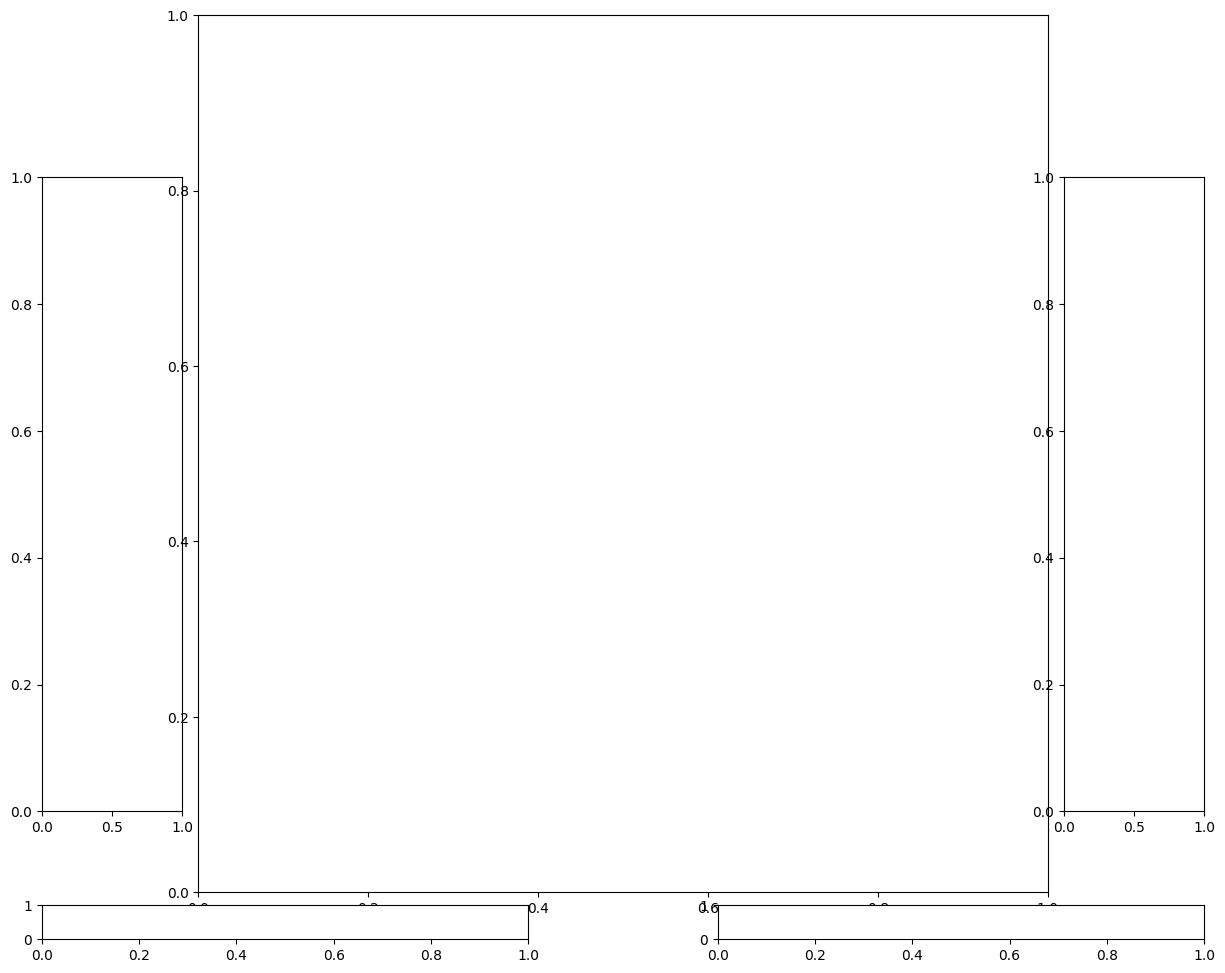

In [ ]:
qhe_results = _run_exp1(qhe_snippets, _qhe_tasks, "qhe", _OUT_QHE)
qb_results  = _run_exp1(qb_snippets,  _qb_tasks,  "qb",  _OUT_QB)

In [ ]:
# ── Experiment1 baseline: Cross benchmark(QHE+QB) +  ONE LLM  ───────────
# Starcoder generated s_quantum vs canonical
# Executes all 20 Starcoder completions per task, computes s_quantum against
# canonical, and writes QHE + QB combined JSON for cross-benchmark analysis.

import statistics as _stats

_SC_QHE = REPO_DIR / "dataset/starcoder_qhe_exec.json"
_SC_QB  = REPO_DIR / "dataset/starcoder_qb_exec.json"
_OUT_SC = REPO_DIR / "dataset/s_quantum/starcoder_s_quantum_QHEQB.json"

_SAMPLE_KEYS = [
    "s_gate_raw", "s_gate_raw_cosine", "s_gate_raw_ratio",
    "s_struct_raw", "s_struct_raw_lcs", "s_struct_raw_kgram",
    "s_struct_wl_raw", "s_struct_wl_kernel_raw", "s_struct_wl_status_raw",
    "s_struct_edge_jaccard_raw",
    "s_gate_transpiled", "s_struct_transpiled",
    "s_struct_wl_transpiled", "s_struct_wl_kernel_transpiled", "s_struct_wl_status_transpiled",
    "s_struct_edge_jaccard_transpiled",
    "s_gate_ast",
    "f", "f_tvd",
    "raw_status", "transpiled_status",
]
_AGG_KEYS = [
    "s_gate_raw", "s_struct_raw",
    "s_struct_wl_raw", "s_struct_edge_jaccard_raw",
    "s_gate_transpiled", "s_struct_transpiled",
    "s_struct_wl_transpiled", "s_struct_edge_jaccard_transpiled",
]


def _run_exp3_s_quantum(sc_path, tasks, benchmark, canonical_code_fn):
    with open(sc_path) as _f:
        sc_records = json.load(_f)

    results = []
    for sc in sc_records:
        task_id     = sc["task_id"]
        entry_point = sc["entry_point"]
        prompt      = sc["prompt"]
        raw_codes   = sc["raw_codes"]       # list[str] len=20
        exec_results = sc["exec_results"]   # list[bool] len=20

        task = tasks.get(task_id)
        if task is None:
            print(f"skip {task_id}: not in task dict")
            continue

        # ── Canonical QC ─────────────────────────────────────────────────
        canonical_code = canonical_code_fn(task)
        kwargs_tokens  = TASK_EXTRA_ARGS.get(task_id, {})
        canon_rec = build_exc_record(
            task_id, "canonical", entry_point, canonical_code,
            kwargs_tokens=kwargs_tokens,
            test_src=task.get("test"),
            include_qc=True,
        )
        canonical_qc  = canon_rec.pop("_qc", None)
        canonical_err = canon_rec.get("error_msg")
        if (canonical_err and "returned" in str(canonical_err)
                and "expected QuantumCircuit" in str(canonical_err)):
            canonical_err = "entry_point does not return QuantumCircuit"

        # ── Per-sample s_quantum ──────────────────────────────────────────
        samples = []
        for idx, body in enumerate(raw_codes):
            full_code = reconstruct_full_code(prompt, body)
            gen_rec = build_exc_record(
                task_id, f"gen_{idx}", entry_point, full_code,
                kwargs_tokens=kwargs_tokens,
                include_qc=True,
            )
            gen_qc  = gen_rec.pop("_qc", None)
            gen_err = gen_rec.get("error_msg")

            pair = compute_pair_metrics(
                reference_qc=canonical_qc,
                candidate_qc=gen_qc,
                reference_code=canonical_code,
                candidate_code=full_code,
                basis_gates=COMMON_BASIS,
                optimization_level=COMMON_OPTIMIZATION_LEVEL,
                seed_transpiler=COMMON_TRANSPILE_SEED,
            )
            samples.append({
                "idx":       idx,
                "exec_ok":   gen_qc is not None,
                "exec_error": gen_err,
                "pass":      bool(exec_results[idx]),
                **{k: pair.get(k) for k in _SAMPLE_KEYS},
            })

        # ── Aggregate mean ± std over valid (exec_ok) samples ────────────
        valid = [s for s in samples if s["exec_ok"]]

        def _agg(key):
            vals = [s[key] for s in valid if s.get(key) is not None]
            if not vals:
                return None, None
            return (
                round(sum(vals) / len(vals), 6),
                round(_stats.stdev(vals), 6) if len(vals) > 1 else 0.0,
            )

        row = {
            "task_id":             task_id,
            "benchmark":           benchmark,
            "canonical_exec_ok":   canonical_qc is not None,
            "canonical_exec_error": canonical_err,
            "n_samples":           len(samples),
            "n_exec_ok":           len(valid),
            "pass_at_1":           round(sum(s["pass"] for s in samples) / len(samples), 4)
                                   if samples else None,
        }
        for key in _AGG_KEYS:
            m, s = _agg(key)
            row[f"{key}_mean"] = m
            row[f"{key}_std"]  = s
        row["samples"] = samples
        results.append(row)

        if len(results) % 20 == 0:
            print(f"  {benchmark.upper()} {len(results)}/{len(sc_records)}")

    return results


# QHE: reconstruct_full_code(prompt, body) for both canonical and generated
# QB:  canonical_solution is already complete code; generated uses reconstruct
_qhe_canon = lambda t: reconstruct_full_code(t["prompt"], t["canonical_solution"])
_qb_canon  = lambda t: t["canonical_solution"]

print("Running QHE (151 tasks × 20 samples)...")
_qhe_sc = _run_exp3_s_quantum(_SC_QHE, _qhe_tasks, "qhe", _qhe_canon)
print(f"QHE done: {len(_qhe_sc)} tasks")

print("Running QB (44 tasks × 20 samples)...")
_qb_sc = _run_exp3_s_quantum(_SC_QB, _qb_tasks, "qb", _qb_canon)
print(f"QB done: {len(_qb_sc)} tasks")

_combined = _qhe_sc + _qb_sc
_OUT_SC.parent.mkdir(parents=True, exist_ok=True)
with open(_OUT_SC, "w") as _f:
    json.dump(_combined, _f, indent=2, default=str)

_n_canon_ok  = sum(1 for r in _combined if r["canonical_exec_ok"])
_n_any_valid = sum(1 for r in _combined if r["n_exec_ok"] > 0)
print(f"\nCombined: {len(_combined)} tasks | canon_ok={_n_canon_ok} | "
      f"tasks_with_valid_gen={_n_any_valid}")
print(f"Saved → {_OUT_SC}")

## Experiment 2: Canonical Rewrite / Metric Validation

Both sides are canonical code executed through the same entry point and kwargs. The original canonical circuit is the reference; the rewritten canonical circuit is the candidate. Functional similarity is read from the same pair result as the equivalence check and is not combined with the structural axes by `max()`.

In [ ]:
if RUN_FRAMEWORK:
    canonical_original_qc, original_error = exec_code(
        entry_point, task_kwargs, canonical_original_code
    )
    canonical_rewrite_qc, rewrite_error = exec_code(
        entry_point, task_kwargs, canonical_rewrite_code
    )

    exp2_metrics = compute_pair_metrics(
        reference_qc=canonical_original_qc,
        candidate_qc=canonical_rewrite_qc,
    )
    equivalence_result = exp2_metrics["functional_details"]
    exp2_s_quantum = s_quantum_axes(exp2_metrics, representation="transpiled")

## Experiment 3: Generated Code / Cross-LLM

Each canonical reference is executed once. Every one of the 20 generated bodies is reconstructed, executed into a `QuantumCircuit`, compared with its corresponding canonical circuit, and retained as a per-generation result. Execution or metric failure remains `None`/`NaN` and is analysed separately.

In [ ]:
if RUN_FRAMEWORK:
    canonical_original_qc, _ = exec_code(
        entry_point, task_kwargs, canonical_original_code
    )
    canonical_rewrite_qc, _ = exec_code(
        entry_point, task_kwargs, canonical_rewrite_code
    )

    original_generation_metrics = []
    for raw_body in original_generation_bodies:  # n = 20
        generated_code = reconstruct_full_code(original_prompt, raw_body)
        generated_qc, error = exec_code(entry_point, task_kwargs, generated_code)
        if generated_qc is None:
            original_generation_metrics.append(make_failed_pair_metrics(error))
            continue
        original_generation_metrics.append(compute_pair_metrics(
            reference_qc=canonical_original_qc,
            candidate_qc=generated_qc,
        ))

    rewrite_generation_metrics = []
    for raw_body in rewrite_generation_bodies:  # n = 20
        generated_code = reconstruct_full_code(rewrite_prompt, raw_body)
        generated_qc, error = exec_code(entry_point, task_kwargs, generated_code)
        if generated_qc is None:
            rewrite_generation_metrics.append(make_failed_pair_metrics(error))
            continue
        rewrite_generation_metrics.append(compute_pair_metrics(
            reference_qc=canonical_rewrite_qc,
            candidate_qc=generated_qc,
        ))

In [ ]:

    original_summary = aggregate_valid_generations(original_generation_metrics)
    rewrite_summary = aggregate_valid_generations(rewrite_generation_metrics)

    # Each metric keeps its own valid set V and m = |V|.
    generation_comparison = {
        "original": original_summary,
        "rewrite": rewrite_summary,
    }